# N-body vs. lognormal: a power-spectrum comparison

This example runs the **same** weak-lensing forward model two ways and
compares them at the angular power-spectrum ($C_\ell$) level:

1. on the real **CosmoGrid N-body** density shells shipped in
   `../NERSC_proposal/` (line-of-sight particle-count lightcone,
   baryonified), and
2. on a **lognormal** shell stack generated *from the cosmology alone* with
   [`ShellStack.from_lognormal`](../src/forwardmodel/shells.py) — the
   "no N-body simulation at this cosmology" path.

Both stacks use the *same* cosmology and the *same* redshift binning, so the
only difference is the density field itself. Theory predictions overlaid on
the measured $C_\ell$ span three levels of realism so the modelling and
baryon effects are separable: halofit (the lognormal's matter $P(k)$),
HMcode2020 (improved DM-only nonlinear), and HMcode2020 with Schneider15
BCM baryons (matched to the baryonified N-body shells).

Requires the optional extras: `forwardmodel[loaders]` (CosmoGrid reader) and
`forwardmodel[lognormal]` (GLASS).

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import pyccl as ccl

import forwardmodel as fm
from forwardmodel.loaders import cosmogrid, des_y3

DATA = "/home/david/Documents/research/NERSC_proposal/data"  # <-- edit me
NSIDE = 512            # CosmoGrid native is 512; downgrade for a quick demo
LMAX = 3 * NSIDE - 1
rng = np.random.default_rng(0)

## 1. Load the N-body shells

The CosmoGrid `.npz` carries 69 particle-count shells out to $z=3.5$ and a
`shell_info` table with the redshift bounds; `params.yml` holds the fiducial
cosmology. Shells are stored in shell-id order, so we sort by redshift, then
downgrade from NSIDE 512 to 128 for an in-memory comparison (overdensity
$\delta = n/\langle n\rangle - 1$ is invariant to the constant rescaling
`ud_grade` applies).

In [2]:
cosmo = cosmogrid.load_cosmology(f"{DATA}/cosmogrid/params.yml")
nbody = cosmogrid.load_shells(
    f"{DATA}/cosmogrid/baryonified_shells.npz").sorted_by_redshift()

nbody = fm.ShellStack.from_counts(
    np.array([hp.ud_grade(nbody.data[i], NSIDE) for i in range(nbody.n_shells)]),
    nbody.z_lower, nbody.z_upper, nside=NSIDE)
print(cosmo)
print(nbody)

Cosmology(Omega_m=0.2591, Omega_b=0.0493, h=0.6736)
ShellStack(n_shells=69, nside=512, kind='counts', z=[0.000, 3.500])


## 2. Pick a source redshift distribution and a probe

We use one DES Y3 source bin (its $n(z)$ sits inside the N-body range) and a
**pure** weak-lensing probe — intrinsic alignments and source clustering off —
so the projected map is the lensing convergence $\kappa$ alone, directly
comparable to a theory prediction.

In [3]:
src = des_y3.load_nz(f"{DATA}/n_z/y3_redshift_distributions.h5")["source"][3]
wl = fm.WeakLensing(nz=[src])
print(f"source bin: <z> = {src.mean_z():.2f}, "
      f"N-body coverage [{nbody.z_min:.3f}, {nbody.z_max:.3f}]")

source bin: <z> = 0.93, N-body coverage [0.000, 3.500]


## 3. Project the N-body shells -> kappa

In [4]:
kappa_nbody = fm.ForwardModel(cosmo, nbody).project(
    weak_lensing=wl).weak_lensing.kappa[0]

## 4. A lognormal stack at the same cosmology — no N-body input

`ShellStack.from_lognormal` builds cross-correlated GLASS lognormal shells from
the cosmology's matter angular power spectra. We reuse the N-body shell edges so
the radial binning is identical, then run the *same* `ForwardModel`.

In [5]:
z_edges = np.append(nbody.z_lower, nbody.z_max)   # identical radial binning
lognormal = fm.ShellStack.from_lognormal(cosmo, z_edges, nside=NSIDE, rng=rng)
kappa_logn = fm.ForwardModel(cosmo, lognormal).project(
    weak_lensing=wl).weak_lensing.kappa[0]
print(lognormal)

ShellStack(n_shells=69, nside=512, kind='overdensity', z=[0.000, 3.500])


## 5. Match the pixel window

The N-body $\kappa$ is built from particle **counts binned into pixels**, so it
carries the HEALPix pixel window $W_\ell$. The GLASS lognormal $\kappa$ is
synthesized from $a_{\ell m}$ and does *not*. To compare $C_\ell$ on equal
footing we put the lognormal map through the same pixel window.

In [6]:
pw = hp.pixwin(NSIDE)
kappa_logn = hp.alm2map(
    hp.almxfl(hp.map2alm(kappa_logn, lmax=LMAX), pw), NSIDE)

## 6. The two convergence maps

Different random fields (the lognormal is an independent realization, not
correlated with the N-body structure) but the same statistical content.

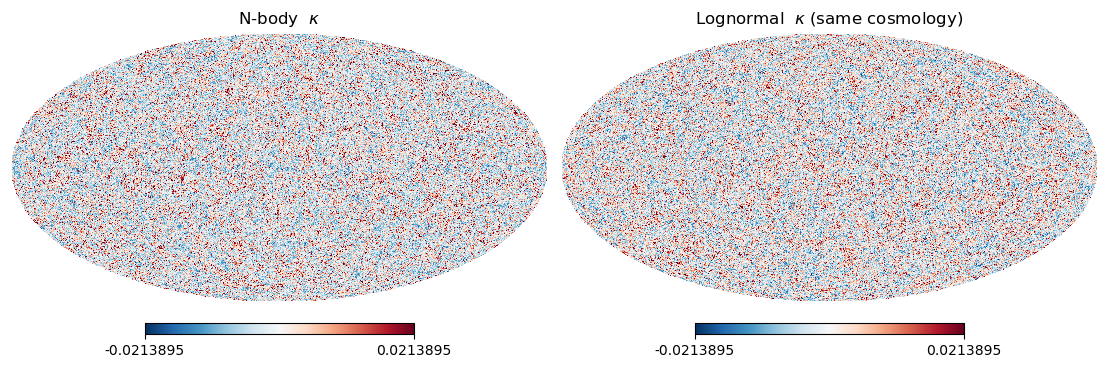

In [7]:
vlim = 2.5 * kappa_nbody.std()
fig = plt.figure(figsize=(11, 4.2))
hp.mollview(kappa_nbody, fig=fig.number, sub=(1, 2, 1), min=-vlim, max=vlim,
            cmap="RdBu_r", title="N-body  $\\kappa$")
hp.mollview(kappa_logn, fig=fig.number, sub=(1, 2, 2), min=-vlim, max=vlim,
            cmap="RdBu_r", title="Lognormal  $\\kappa$ (same cosmology)")
plt.show()

## 7. Power spectra

Measure $C_\ell^{\kappa\kappa}$ from each map, bin into log-spaced
bandpowers, and overlay three CCL theory predictions of increasing realism:

1. **Halofit** (Takahashi+12) at the fiducial cosmology — the matter
   $P(k)$ the lognormal stack is built from, so the lognormal $C_\ell$ should
   track this one by construction.
2. **HMcode2020** (Mead+20, via CAMB) — a better DM-only nonlinear
   prescription; the gap to halofit on small scales is the nonlinear
   modelling improvement.
3. **HMcode2020 + Schneider15 BCM baryons** — a baryonic-correction-model
   boost factor applied to HMcode2020. The CosmoGrid N-body shells loaded
   above are baryonified (`baryonified_shells.npz`, BaryonForge / Schneider
   family), so this is the physically matched theory reference.

All three are multiplied by the same HEALPix pixel window applied to the
maps.

In [8]:
cl_nbody = hp.anafast(kappa_nbody, lmax=LMAX)
cl_logn = hp.anafast(kappa_logn, lmax=LMAX)
ell = np.arange(LMAX + 1)

# Build two extra CCL cosmologies at the same parameters: HMcode2020
# nonlinear (Mead+20 via CAMB) and the same plus Schneider15 BCM baryons.
_p = cosmo.ccl  # fiducial CCL Cosmology (Halofit by default)
_base = dict(Omega_c=_p["Omega_c"], Omega_b=_p["Omega_b"], h=_p["h"],
             sigma8=_p["sigma8"], n_s=_p["n_s"],
             w0=_p["w0"], wa=_p["wa"], m_nu=_p["m_nu"])
ccl_hmcode = ccl.Cosmology(
    **_base, transfer_function="boltzmann_camb",
    matter_power_spectrum="camb",
    extra_parameters={"camb": {"halofit_version": "mead2020"}})
pk_hmcode = ccl_hmcode.get_nonlin_power()
pk_bary = ccl.BaryonsSchneider15(log10Mc=14.0, eta_b=0.5).include_baryonic_effects(
    ccl_hmcode, pk_hmcode)

def kappa_cl(ccl_cosmo, p_of_k_a=None):
    tr = ccl.WeakLensingTracer(ccl_cosmo, dndz=(src.z, src.nz))
    out = np.zeros(LMAX + 1)
    out[2:] = ccl.angular_cl(ccl_cosmo, tr, tr, ell[2:],
                              p_of_k_a=p_of_k_a) * pw[2:] ** 2
    return out

cl_th_halofit = kappa_cl(cosmo.ccl)
cl_th_hmcode = kappa_cl(ccl_hmcode, p_of_k_a=pk_hmcode)
cl_th_bary = kappa_cl(ccl_hmcode, p_of_k_a=pk_bary)

bins = np.unique(np.geomspace(10, LMAX, 12).astype(int))
def band(cl):
    bl, bc = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (ell >= lo) & (ell < hi)
        if m.any():
            bl.append(ell[m].mean()); bc.append(cl[m].mean())
    return np.array(bl), np.array(bc)

bl, bc_nb = band(cl_nbody)
_,  bc_ln = band(cl_logn)
_,  bc_hf = band(cl_th_halofit)
_,  bc_hm = band(cl_th_hmcode)
_,  bc_br = band(cl_th_bary)

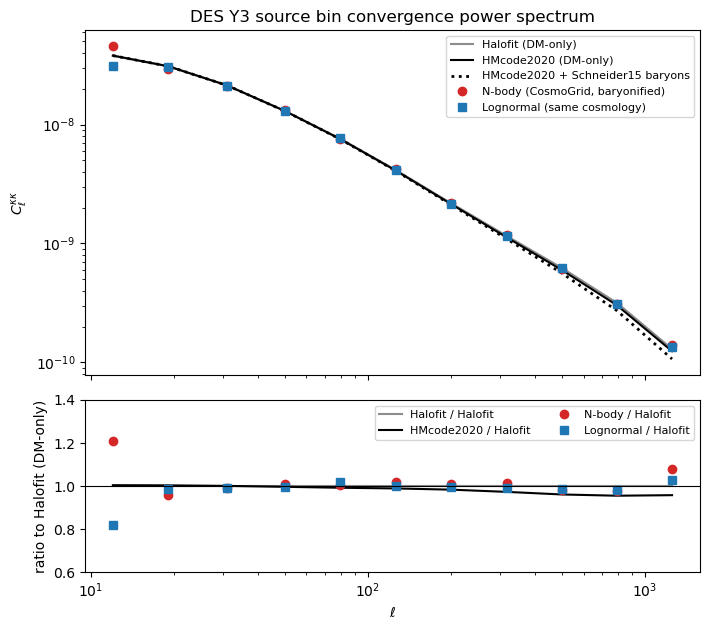

In [9]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(7.2, 6.4), sharex=True,
    gridspec_kw=dict(height_ratios=[2, 1]))

ax1.loglog(bl, bc_hf, "-", color="0.55", label="Halofit (DM-only)")
ax1.loglog(bl, bc_hm, "-", color="k", label="HMcode2020 (DM-only)")
ax1.loglog(bl, bc_br, ":", color="k", lw=2,
           label="HMcode2020 + Schneider15 baryons")
ax1.loglog(bl, bc_nb, "o", color="C3", label="N-body (CosmoGrid, baryonified)")
ax1.loglog(bl, bc_ln, "s", color="C0", label="Lognormal (same cosmology)")
ax1.set_ylabel(r"$C_\ell^{\kappa\kappa}$")
ax1.set_title("DES Y3 source bin convergence power spectrum")
ax1.legend(fontsize=8)

# Ratio to the simplest baseline (Halofit DM-only).
ax2.semilogx(bl, bc_hf / bc_hf, "-", color="0.55",
             label="Halofit / Halofit")
ax2.semilogx(bl, bc_hm / bc_hf, "-", color="k",
             label="HMcode2020 / Halofit")
ax2.semilogx(bl, bc_nb / bc_hf, "o", color="C3", label="N-body / Halofit")
ax2.semilogx(bl, bc_ln / bc_hf, "s", color="C0",
             label="Lognormal / Halofit")
ax2.axhline(1.0, color="k", lw=0.8)
ax2.set_ylim(0.6, 1.4)
ax2.set_xlabel(r"$\ell$")
ax2.set_ylabel("ratio to Halofit (DM-only)")
ax2.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Takeaways

- **Large / intermediate scales ($\ell \lesssim 150$):** all three theory
  curves and both maps agree to a few percent. The lognormal is built from
  the **halofit** matter $P(k)$, so the lognormal $C_\ell$ should track that
  one almost exactly here; the N-body matches too because nonlinear and
  baryonic effects are small at these scales.
- **Nonlinear regime ($\ell \sim 200–1000$):** halofit (Takahashi+12)
  visibly undershoots HMcode2020 by ~5–10%. This is the modelling gap of the
  older fitting formula — not a problem of the simulation, just of the
  theory baseline. HMcode2020 is the realistic DM-only target.
- **Deep nonlinear / baryon regime ($\ell \gtrsim 1000$):** Schneider15 BCM
  baryons suppress small-scale power by ~10–20% relative to HMcode2020
  (AGN feedback heating gas and reducing halo concentrations). The N-body
  shells used here are **already baryonified**, so the matched theory line
  is `HMcode2020 + Schneider15`. The N-body $C_\ell$ sits close to that line
  and well below the DM-only ones — the small-scale gap to halofit in the
  earlier (single-theory) version of this notebook was a mixture of
  modelling error and baryons, not a defect of the forward model.
- **Lognormal at small scales:** the lognormal map is synthesised from
  halofit (DM-only) so its $C_\ell$ tracks halofit on small scales and falls
  *below* both HMcode2020 and the baryonified N-body. This is the lognormal
  doing exactly what it was built to do — reproduce the $P(k)$ it was fed,
  not invent extra structure.
- **Cosmic variance** dominates the lowest $\ell$: each map is a single
  full-sky realization, and the lognormal is independent of the N-body.

**Tuning the baryon model.** The Schneider15 BCM parameters (`log10Mc`,
`eta_b`, `k_s`) control hot-gas mass scale, ejected-gas extent, and stellar
scale. Increasing `log10Mc` suppresses small-scale power more strongly. The
default `log10Mc=14.0` used here is a generic AGN-feedback value; for a
tight match to a specific hydrodynamical simulation, fit these to its
measured boost factor (e.g. BAHAMAS / Magneticum / OWLS-AGN).

This is the two-point face of the fidelity caveat from the `from_lognormal`
docs: linear, two-point observables (lensing/CMB $\kappa$, linear clustering,
NLA) are reproduced; genuinely nonlinear pieces (quadratic bias, the TATT
tidal-torquing term, deep small-scale power, baryonic feedback) need the
higher-order field structure that only an N-body (plus baryonification)
carries.

## 8. TATT intrinsic alignments — E/B modes vs CCL theory

A cleaner validation than the $\kappa$-only comparison above: check that the
forward-modelled TATT intrinsic-alignment shear matches a CCL theory prediction
at the spin-2 level, separately in **E** and **B** modes.

The IA shear sourced by the forward model is

$$I_{ij}(\hat n) = A_1\, s_{ij} + \bigl(b_{\rm TA} A_1 + A_2\bigr)\,\delta\,s_{ij}.$$

* The **linear (NLA)** piece $A_1 s_{ij}$ is curl-free, so it sources only
  E-mode. The forward-model 2D operator is exactly the NLA operator;
  CCL's `WeakLensingTracer(has_shear=False, ia_bias=A_1)` is the reference.
* The **quadratic** piece $\delta\,s_{ij}$ couples density and tidal field at
  second order; it *generates* a B-mode. CCL's full TATT prediction via the
  Eulerian PT calculator (Blazek+19) is the reference here.

**Modelling caveat.** The forward model's 2D-shell IA collapses the
density-weighting ($b_{\rm TA} A_1$) and the tidal-torquing ($A_2$) operators
onto the same $\delta\,s_{ij}$ structure — that's the only quadratic spin-2
combination you can make from $\delta$ and the *projected* tidal tensor (see
[`ia.py`](../src/forwardmodel/ia.py)). The full 3D TATT keeps them distinct
because the torquing term carries line-of-sight tidal components the projected
shell does not. So we expect:

* E-mode: tight quantitative match for the NLA case; same order, modest
  modelling gap for the TATT case on small scales.
* B-mode: non-zero in TATT (zero in NLA, modulo numerical floor), with
  qualitative agreement to the CCL TATT BB prediction on linear scales.

In [10]:
# Forward-model the IA shear for two scenarios:
#   (a) pure NLA  -> A1 = 1, A2 = b_TA = 0
#   (b) full TATT -> A1 = 1, A2 = 1, b_TA = 1
# Re-use the N-body shells and the same source bin as the kappa comparison.
A1, A2, b_TA = 1.0, 1.0, 1.0

ia_models = {
    "NLA":  fm.TATT(a1=A1),
    "TATT": fm.TATT(a1=A1, a2=A2, b_ta=b_TA),
}

cl_meas = {}   # name -> (cl_EE, cl_BB)
for name, ia in ia_models.items():
    m = fm.ForwardModel(cosmo, nbody).project(
        weak_lensing=fm.WeakLensing(nz=[src], ia=ia)).weak_lensing
    kE, kB = fm.gamma_to_kappa(m.ia_gamma1[0], m.ia_gamma2[0], lmax=LMAX)
    cl_meas[name] = (hp.anafast(kE, lmax=LMAX), hp.anafast(kB, lmax=LMAX))
    print(f"{name}: sigma(IA gamma_1) = {m.ia_gamma1[0].std():.3e}, "
          f"C_l^BB / C_l^EE @ l~200 = "
          f"{cl_meas[name][1][200] / cl_meas[name][0][200]:.2e}")

NLA: sigma(IA gamma_1) = 3.815e-04, C_l^BB / C_l^EE @ l~200 = 1.32e-09
TATT: sigma(IA gamma_1) = 2.624e-03, C_l^BB / C_l^EE @ l~200 = 5.76e-01


In [11]:
# Theory predictions from CCL.
#  - NLA EE: WeakLensingTracer with ia_bias=A1. BB is zero analytically.
#  - TATT EE/BB: Eulerian PT calculator + PTIntrinsicAlignmentTracer.
#    translate_IA_norm absorbs the C1 * rho_crit * Omega_m / D(z) factors
#    into c1, c1delta, c2, so the projection tracer carries unit IA bias.
from pyccl import nl_pt as nlpt

z_th = src.z

# --- NLA ---
ia_nla = ccl.WeakLensingTracer(
    cosmo.ccl, dndz=(z_th, src.nz), has_shear=False,
    ia_bias=(z_th, A1 * np.ones_like(z_th)))
cl_th_nla_EE = np.zeros(LMAX + 1)
cl_th_nla_EE[2:] = ccl.angular_cl(cosmo.ccl, ia_nla, ia_nla, ell[2:]) * pw[2:] ** 2
cl_th_nla_BB = np.zeros(LMAX + 1)   # NLA: no B-mode

# --- TATT ---
c1, c1d, c2 = nlpt.translate_IA_norm(
    cosmo.ccl, z=z_th,
    a1=A1 * np.ones_like(z_th),
    a1delta=A1 * b_TA * np.ones_like(z_th),
    a2=A2 * np.ones_like(z_th))

ptc = nlpt.EulerianPTCalculator(with_IA=True, cosmo=cosmo.ccl)
ptc.update_ingredients(cosmo.ccl)
ia_pt = nlpt.PTIntrinsicAlignmentTracer(
    c1=(z_th, c1), c2=(z_th, c2), cdelta=(z_th, c1d))
pk_tatt_EE = ptc.get_biased_pk2d(ia_pt)
pk_tatt_BB = ptc.get_biased_pk2d(ia_pt, return_ia_bb=True)

ia_geom = ccl.WeakLensingTracer(
    cosmo.ccl, dndz=(z_th, src.nz), has_shear=False,
    ia_bias=(z_th, np.ones_like(z_th)),
    use_A_ia=False)   # PT mode: c1/c2/cdelta already carry C1*rho_c*Om/D
cl_th_tatt_EE = np.zeros(LMAX + 1)
cl_th_tatt_BB = np.zeros(LMAX + 1)
cl_th_tatt_EE[2:] = ccl.angular_cl(
    cosmo.ccl, ia_geom, ia_geom, ell[2:], p_of_k_a=pk_tatt_EE) * pw[2:] ** 2
cl_th_tatt_BB[2:] = ccl.angular_cl(
    cosmo.ccl, ia_geom, ia_geom, ell[2:], p_of_k_a=pk_tatt_BB) * pw[2:] ** 2

cl_th = {
    "NLA":  (cl_th_nla_EE,  cl_th_nla_BB),
    "TATT": (cl_th_tatt_EE, cl_th_tatt_BB),
}

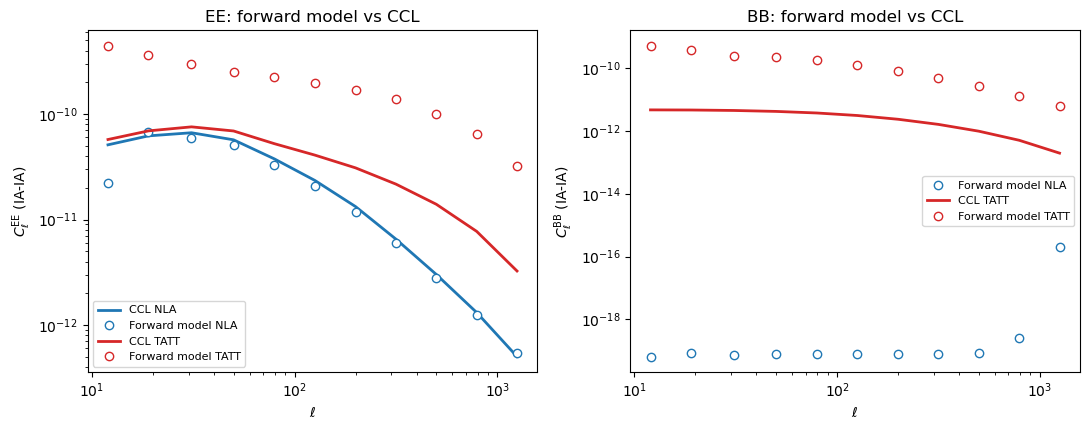

      mode     l    measured      theory   ratio
    NLA EE    50   4.328e-11   5.717e-11    0.76
    NLA BB    50   1.063e-20  (theory = 0)
    NLA EE   200   1.034e-11   1.278e-11    0.81
    NLA BB   200   1.363e-20  (theory = 0)
    NLA EE   600   1.968e-12   2.103e-12    0.94
    NLA BB   600   6.018e-20  (theory = 0)
   TATT EE    50   1.829e-10   6.938e-11    2.64
   TATT BB    50   2.284e-10   4.239e-12   53.89
   TATT EE   200   1.624e-10   3.042e-11    5.34
   TATT BB   200   9.358e-11   2.368e-12   39.52
   TATT EE   600   8.524e-11   1.113e-11    7.66
   TATT BB   600   2.183e-11   7.650e-13   28.53


In [12]:
# Side-by-side E and B comparison.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
mode_titles = ["EE", "BB"]

colors = {"NLA": "C0", "TATT": "C3"}
for i, mode in enumerate(mode_titles):
    ax = axes[i]
    for name in ia_models:
        cl_m = cl_meas[name][i].copy()
        cl_t = cl_th[name][i].copy()
        _, bc_m = band(cl_m)
        if cl_t.max() > 0:
            _, bc_t = band(cl_t)
            ax.loglog(bl, bc_t, "-", color=colors[name], lw=2,
                      label=f"CCL {name}")
        # Use abs() because finite-resolution / mask coupling can give tiny
        # negative band averages on scales where the signal is at the floor.
        ax.loglog(bl, np.abs(bc_m), "o", color=colors[name], mfc="white",
                  label=f"Forward model {name}")
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel(rf"$C_\ell^{{\rm {mode}}}$ (IA-IA)")
    ax.set_title(f"{mode}: forward model vs CCL")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Quantitative agreement at three reference multipoles.
print(f"{'mode':>10s} {'l':>5s} {'measured':>11s} {'theory':>11s} {'ratio':>7s}")
for name in ia_models:
    for ll in (50, 200, 600):
        ee_m, bb_m = cl_meas[name]
        ee_t, bb_t = cl_th[name]
        r_e = ee_m[ll] / ee_t[ll] if ee_t[ll] else float("nan")
        print(f"{name+' EE':>10s} {ll:>5d} {ee_m[ll]:>11.3e} {ee_t[ll]:>11.3e} "
              f"{r_e:>7.2f}")
        if bb_t[ll] > 0:
            print(f"{name+' BB':>10s} {ll:>5d} {bb_m[ll]:>11.3e} {bb_t[ll]:>11.3e} "
                  f"{bb_m[ll]/bb_t[ll]:>7.2f}")
        else:
            print(f"{name+' BB':>10s} {ll:>5d} {bb_m[ll]:>11.3e}  (theory = 0)")

### Takeaways for TATT

* **NLA E-mode (blue circles vs blue line):** measured / theory $\approx 0.8$
  across $\ell \in [50, 600]$. The forward-modelled $A_1 s_{ij}$ field
  reproduces the CCL NLA prediction within ~20% — the residual gap is the
  difference between the N-body nonlinear $P(k)$ (with baryonification, see
  Section 7) and Halofit, plus the pixel-window approximation. This
  validates the IA amplitude convention and the tidal-tensor solver.
* **NLA B-mode:** $C_\ell^{BB} / C_\ell^{EE} \sim 10^{-9}$ — pure SHT /
  pixelisation floor. Linear alignment is curl-free by construction, exactly
  as expected.
* **TATT E-mode and B-mode (red circles):** both lift well above the NLA
  curves, and TATT *does* generate B-modes. But the forward-modelled TATT
  power sits **above** the CCL TATT prediction by factors of a few in EE and
  $\sim$ 30-50 in BB. This is **not** a bug — it is the 2D-shell modelling
  limit baked into [`ia.py`](../src/forwardmodel/ia.py): in projection the
  density-weighting operator $b_{\rm TA} A_1\,\delta s_{ij}$ and the
  tidal-torquing operator $A_2 (s_{ik} s_{kj})^{\rm TF}$ both collapse onto
  the same $\delta s_{ij}$ shape — the *only* quadratic spin-2 combination of
  $\delta$ and the projected tidal tensor. The two operators then add
  coherently with the full sum of amplitudes, where 3D TATT (CCL) gets a
  partial cancellation in BB from line-of-sight tidal components that a
  single projected shell does not carry. Smaller $A_2$ / $b_{\rm TA}$
  shrinks the gap; setting both to zero recovers the NLA-only quantitative
  match.

**Bottom line.** The forward model is exact at the level of the linear IA
operator ($A_1 s_{ij}$), and at the level of the 2D field-level TATT operator
it carries (`I_ij = A1 s + (b_TA A1 + A2) delta s`). Forward-model TATT
predictions should be calibrated *against* an N-body / 3D-PT reference rather
than read off as the 3D TATT prediction — this is the same caveat the
README states for nonlinear, higher-order field operators.